# Descripción del dataset y su origen

**Proyecto:** Predicción de la asistencia actual al nivel superior en jóvenes de 18 a 24 años con secundario completo (EPH – INDEC)
**Autora:** Liliana Elizabeth Iñigo · **Materia:** Aprendizaje Automático

Esta notebook documenta de dónde salen los datos y cómo se arma el dataset del proyecto:

1. Origen de los datos y archivos utilizados
2. Carga de las bases de personas y de hogares
3. Vinculación de cada joven con su hogar y con el jefe o jefa de hogar
4. Delimitación de la población de estudio
5. Construcción de la variable objetivo
6. Tratamiento del panel (personas que aparecen en más de un trimestre)
7. Variables excluidas por fuga de información
8. Descripción del dataset final: instancias, columnas y tipos de datos

El mismo procesamiento está en el script `asistencia_superior/dataset.py`, que genera los archivos de `data/interim` y `data/processed`.

## Planteo de la predicción

- **Variable objetivo:** `asiste_superior` (1 = asiste actualmente a un estudio superior · 0 = no asiste actualmente).
- **Cada fila** es un joven de 18 a 24 años con secundario completo y sin estudio superior terminado, con su situación y la de su hogar en el trimestre en que fue encuestado (una sola fila por persona).
- **Momento de la predicción:** el de la encuesta. Solo se usan datos que pueden conocerse sin saber si el joven asiste: características personales, del hogar, del jefe/a y ubicación. Se excluye todo lo que contiene la respuesta o es consecuencia de estudiar (ver sección 7).
- **Dos tiempos:**
  1. **Uso:** estimar la asistencia de un joven a partir de sus datos y los de su hogar.
  2. **Evaluación y reentrenamiento:** cada trimestre el INDEC publica una nueva EPH con la respuesta real; con ella se puede comparar lo predicho con lo observado y reentrenar el modelo. En la Entrega 3 se puede simular entrenando con 2025 y evaluando con el 1T 2026.

## 1. Origen de los datos

- **Fuente:** Encuesta Permanente de Hogares (EPH), modalidad continua, Instituto Nacional de Estadística y Censos (INDEC).
- **Sitio de descarga:** https://www.indec.gob.ar/indec/web/Institucional-Indec-BasesDeDatos
- **Trimestres:** 2.º, 3.º y 4.º trimestre de 2025 y 1.er trimestre de 2026 (los cuatro más recientes publicados al momento de la descarga).
- **Fecha de descarga:** 22 de octubre de 2026.
- **Formato:** archivos de texto separados por punto y coma (`;`). Por cada trimestre hay una base de **personas** (`usu_individual_*`) y una de **hogares** (`usu_hogar_*`).
- **Cobertura geográfica:** 31 aglomerados urbanos (32 códigos de `AGLOMERADO`, porque el Gran Buenos Aires se divide en Ciudad de Buenos Aires y partidos del conurbano). La EPH no cubre la población rural, por eso el estudio habla de jóvenes de los aglomerados urbanos relevados y no de todos los jóvenes del país.
- **Licencia de uso:** datos públicos del INDEC; se cita la fuente.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 40)
RAW = Path("../data/raw")
TRIMESTRES = ["T225", "T325", "T425", "T126"]
CLAVE_HOGAR = ["CODUSU", "NRO_HOGAR", "ANO4", "TRIMESTRE"]
CLAVE_PERSONA = ["CODUSU", "NRO_HOGAR", "COMPONENTE"]

## 2. Carga de las bases

Cada archivo se lee con separador `;`. Algunos trimestres traen los encabezados entre comillas y otros no; `pandas` los lee igual.

In [2]:
personas_t = {t: pd.read_csv(RAW / f"usu_individual_{t}.txt", sep=";", low_memory=False) for t in TRIMESTRES}
hogares_t = {t: pd.read_csv(RAW / f"usu_hogar_{t}.txt", sep=";", low_memory=False) for t in TRIMESTRES}

resumen = pd.DataFrame({
    "trimestre": TRIMESTRES,
    "personas (filas)": [len(personas_t[t]) for t in TRIMESTRES],
    "columnas base personas": [personas_t[t].shape[1] for t in TRIMESTRES],
    "hogares (filas)": [len(hogares_t[t]) for t in TRIMESTRES],
    "columnas base hogares": [hogares_t[t].shape[1] for t in TRIMESTRES],
})
resumen.loc["Total"] = ["", resumen["personas (filas)"].sum(), "", resumen["hogares (filas)"].sum(), ""]
resumen

,trimestre,personas (filas),columnas base personas,hogares (filas),columnas base hogares
0,T225,46086,235,16169,98
1,T325,44946,235,15860,98
2,T425,43703,235,15534,98
3,T126,43739,234,15447,98
Total,,178474,,63010,


**Diferencia de diseño entre trimestres:** la base de personas del 1.er trimestre de 2026 tiene una columna menos. Se verifica cuál es:

In [3]:
cols_2025 = set(personas_t["T425"].columns)
cols_2026 = set(personas_t["T126"].columns)
print("Columnas que están en 2025 y no en 1T 2026:", sorted(cols_2025 - cols_2026))
print("Columnas que están en 1T 2026 y no en 2025:", sorted(cols_2026 - cols_2025))

Columnas que están en 2025 y no en 1T 2026: ['CAT_INAC']
Columnas que están en 1T 2026 y no en 2025: []


La columna que falta es `CAT_INAC` (categoría de inactividad). No afecta al proyecto porque se excluye de todas formas: una de sus categorías es "estudiante" (ver sección 7).

In [4]:
personas = pd.concat(personas_t.values(), ignore_index=True)
hogares = pd.concat(hogares_t.values(), ignore_index=True)
print("Personas (4 trimestres):", f"{len(personas):,}")
print("Hogares  (4 trimestres):", f"{len(hogares):,}")

Personas (4 trimestres): 178,474
Hogares  (4 trimestres): 63,010


## 3. Vinculación persona – hogar – jefe o jefa de hogar

- **Persona con su hogar:** las dos bases comparten `CODUSU` (vivienda) y `NRO_HOGAR` (hogar dentro de la vivienda). Como hay cuatro trimestres, se agregan `ANO4` y `TRIMESTRE` a la clave.
- **Persona con el jefe o jefa de hogar:** dentro del mismo hogar, el jefe o jefa es quien tiene `CH03 = 1` (relación de parentesco). De esa fila se toman su nivel educativo (`NIVEL_ED`), su sexo (`CH04`) y su condición de actividad (`ESTADO`).

In [5]:
hogares_por_clave = hogares.duplicated(CLAVE_HOGAR).sum()
jefes = personas.loc[personas["CH03"] == 1, CLAVE_HOGAR + ["NIVEL_ED", "CH04", "ESTADO"]]
print("Claves de hogar repetidas en la base de hogares:", hogares_por_clave)
print("Hogares con más de un jefe/a:", jefes.duplicated(CLAVE_HOGAR).sum())

claves_personas = personas[CLAVE_HOGAR].drop_duplicates()
con_hogar = claves_personas.merge(hogares[CLAVE_HOGAR], how="inner").shape[0]
con_jefe = claves_personas.merge(jefes[CLAVE_HOGAR], how="inner").shape[0]
print(f"Hogares de la base de personas que encuentran su fila en la base de hogares: {con_hogar / len(claves_personas):.1%}")
print(f"Hogares de la base de personas que tienen un jefe/a identificado: {con_jefe / len(claves_personas):.1%}")

Claves de hogar repetidas en la base de hogares: 0
Hogares con más de un jefe/a: 0
Hogares de la base de personas que encuentran su fila en la base de hogares: 100.0%
Hogares de la base de personas que tienen un jefe/a identificado: 100.0%


## 4. Población de estudio

Se trabaja con jóvenes de **18 a 24 años** (`CH06`) que **terminaron el secundario y no completaron un estudio superior**.

Para el filtro se usa `NIVEL_ED` (nivel educativo alcanzado), según el diccionario de la EPH:

| NIVEL_ED | Significado | ¿Se incluye? |
|---|---|---|
| 1, 2, 3, 7 | Primaria incompleta/completa, secundaria incompleta, sin instrucción | No (no terminaron el secundario) |
| **4** | Secundario completo | **Sí** |
| **5** | Superior universitario incompleto | **Sí** |
| 6 | Superior universitario completo | No (ya terminaron un estudio superior) |

Se incluye el código 5 porque quien terminó el secundario y **está cursando** el nivel superior figura con `NIVEL_ED = 5`, no con 4. Si se filtrara solo por 4, quedarían afuera justamente los jóvenes que asisten.

Se excluye el código 6 porque no asistir actualmente no significa que no hayan accedido: ya terminaron una carrera.

In [6]:
edad_ok = personas["CH06"].between(18, 24)
conteo_nivel = personas.loc[edad_ok, "NIVEL_ED"].value_counts().sort_index()
conteo_nivel.index = conteo_nivel.index.map({1: "1 Primaria incompleta", 2: "2 Primaria completa",
    3: "3 Secundaria incompleta", 4: "4 Secundaria completa", 5: "5 Superior incompleto",
    6: "6 Superior completo", 7: "7 Sin instrucción"})
conteo_nivel.rename("jóvenes de 18 a 24 años").to_frame()

,jóvenes de 18 a 24 años
NIVEL_ED,
1 Primaria incompleta,353
2 Primaria completa,430
3 Secundaria incompleta,4638
4 Secundaria completa,5609
5 Superior incompleto,8274
6 Superior completo,502
7 Sin instrucción,25


In [7]:
poblacion = personas[edad_ok & personas["NIVEL_ED"].isin([4, 5])].copy()
excluidos_superior_completo = (edad_ok & (personas["NIVEL_ED"] == 6)).sum()
print(f"Observaciones en la población de estudio: {len(poblacion):,}")
print(f"Excluidos por tener un estudio superior completo (NIVEL_ED = 6): {excluidos_superior_completo:,}")
poblacion.groupby(["ANO4", "TRIMESTRE"]).size().rename("observaciones").to_frame()

Observaciones en la población de estudio: 13,883
Excluidos por tener un estudio superior completo (NIVEL_ED = 6): 502


observaciones
ANO4 TRIMESTRE               
2025 2                   3726
     3                   3437
     4                   3223
2026 1                   3497

## 5. Variable objetivo: `asiste_superior`

La respuesta surge directamente de dos preguntas de la encuesta:

- `CH10`: ¿asiste o asistió a algún establecimiento educativo? (1 = sí, asiste · 2 = no asiste, pero asistió · 3 = nunca asistió)
- `CH12`: ¿cuál es el nivel más alto que cursa o cursó? (6 = terciario · 7 = universitario · 8 = posgrado universitario, entre otros)

`CH12` también registra niveles cursados **en el pasado**, por eso se interpreta siempre junto con `CH10`:

- **`asiste_superior = 1`**: asiste actualmente (`CH10 = 1`) y el nivel que cursa es terciario, universitario o posgrado (`CH12` = 6, 7 u 8).
- **`asiste_superior = 0`**: no asiste actualmente al nivel superior.

La variable describe la situación **en el momento de la encuesta**: no permite afirmar qué hará el joven en el futuro.

In [8]:
poblacion["asiste_superior"] = ((poblacion["CH10"] == 1) & poblacion["CH12"].isin([6, 7, 8])).astype(int)
pd.crosstab([poblacion["CH10"], poblacion["CH12"]], poblacion["asiste_superior"],
            margins=True, margins_name="Total")

asiste_superior     0     1  Total
CH10  CH12                        
0     0             1     0      1
1     6             0  1722   1722
      7             0  6063   6063
      99            1     0      1
2     2             1     0      1
      3             2     0      2
      4          5268     0   5268
      5           335     0    335
      6           149     0    149
      7           339     0    339
      99            1     0      1
9     99            1     0      1
Total            6098  7785  13883

Hay **un solo caso** que declara asistir (`CH10 = 1`) con nivel sin dato (`CH12 = 99`), y dos casos sin dato en `CH10` (códigos 0 y 9). Como no puede saberse si asisten al nivel superior, quedan en la clase 0. Son 3 registros de 13.883, no alteran los resultados.

También se ve que 149 jóvenes cursaron un terciario y 339 una carrera universitaria pero **ya no asisten** (`CH10 = 2`): quedan en la clase 0 porque la variable mide la asistencia actual.

`CH10`, `CH12` y `NIVEL_ED` se usan **solo** para definir la población y la respuesta: no se guardan como predictoras en el dataset final.

## 6. Datos del hogar y del jefe o jefa

Se agregan a cada joven:

- de la **base de hogares**: tipo de vivienda (`IV1`), cantidad de ambientes (`II1`), régimen de tenencia (`II7`), cantidad de personas (`IX_TOT`) y de menores de 10 años (`IX_MEN10`);
- del **jefe o jefa de hogar**: nivel educativo, sexo y condición de actividad.

**Cuidado con los jóvenes que son ellos mismos jefe/a o cónyuge del jefe/a** (`CH03` = 1 o 2): para ellos, "educación del jefe/a" sería su propio nivel educativo o el de su pareja, que dice mucho sobre la respuesta. En esos casos los datos del jefe/a quedan vacíos y se marca la variable `es_jefe_o_conyuge = 1`.

In [9]:
datos_jefe = jefes.rename(columns={"NIVEL_ED": "jefe_nivel_ed", "CH04": "jefe_sexo", "ESTADO": "jefe_estado"})
poblacion = poblacion.merge(hogares[CLAVE_HOGAR + ["IV1", "II1", "II7", "IX_TOT", "IX_MEN10"]],
                            on=CLAVE_HOGAR, how="left", validate="m:1")
poblacion = poblacion.merge(datos_jefe, on=CLAVE_HOGAR, how="left", validate="m:1")

poblacion["es_jefe_o_conyuge"] = poblacion["CH03"].isin([1, 2]).astype(int)
for col in ["jefe_nivel_ed", "jefe_sexo", "jefe_estado"]:
    poblacion.loc[poblacion["es_jefe_o_conyuge"] == 1, col] = np.nan

print("Jóvenes que son jefe/a o cónyuge:", poblacion["es_jefe_o_conyuge"].sum())
print("Jóvenes sin datos de hogar:", poblacion["IX_TOT"].isna().sum())

Jóvenes que son jefe/a o cónyuge: 1790
Jóvenes sin datos de hogar: 0


### Ingresos y hacinamiento

- En la EPH, cuando el hogar no responde los ingresos, `ITF` (ingreso total familiar) vale 0 y `DECCFR` (decil) vale 12. Esos casos **no** son hogares sin ingresos: se marcan con `ingresos_sin_respuesta = 1` y el ingreso queda vacío, para imputarlo en la etapa de preparación.
- El ingreso del joven (`P47T`) incluye becas de estudio y cuota alimentaria, que aparecen casi solo entre quienes estudian (sección 7). Por eso se calcula el **ingreso per cápita del resto del hogar** (sin los ingresos propios del joven).
- **Hacinamiento:** personas por ambiente de uso exclusivo del hogar (`IX_TOT / II1`).

In [10]:
sin_respuesta = poblacion["DECCFR"] == 12
poblacion["ingresos_sin_respuesta"] = sin_respuesta.astype(int)
ingreso_propio = poblacion["P47T"].where(poblacion["P47T"] >= 0)   # -9 = sin dato
resto = (poblacion["ITF"] - ingreso_propio).where(~sin_respuesta)
otros = (poblacion["IX_TOT"] - 1).replace(0, np.nan)
poblacion["ingreso_resto_hogar_pc"] = (resto / otros).clip(lower=0)
poblacion.loc[poblacion["IX_TOT"] == 1, "ingreso_resto_hogar_pc"] = 0.0
poblacion["personas_por_ambiente"] = poblacion["IX_TOT"] / poblacion["II1"].where(poblacion["II1"] > 0)

print(f"Hogares sin respuesta de ingresos: {sin_respuesta.mean():.1%} de las observaciones")
print(f"Ingreso propio del joven sin dato (P47T = -9): {(poblacion['P47T'] == -9).mean():.1%}")

Hogares sin respuesta de ingresos: 29.5% de las observaciones
Ingreso propio del joven sin dato (P47T = -9): 9.6%


## 7. Variables excluidas por fuga de información

Una variable "filtra" la respuesta cuando contiene, directa o indirectamente, la información que se quiere predecir. Se revisaron estas:

In [11]:
print("NIVEL_ED (nivel educativo del joven) vs. asiste_superior:")
print(pd.crosstab(poblacion["NIVEL_ED"], poblacion["asiste_superior"], normalize="index").round(3))

NIVEL_ED (nivel educativo del joven) vs. asiste_superior:
asiste_superior      0      1
NIVEL_ED                     
4                1.000  0.000
5                0.059  0.941


In [12]:
tiene_beca = (poblacion["V11_01_M"] > 0) | (poblacion["V11_02_M"] > 0)
tiene_cuota = poblacion["V12_M"] > 0
print("Recibe monto en V11_01_M / V11_02_M (beca de estudio):")
print(pd.crosstab(tiene_beca, poblacion["asiste_superior"], margins=True))
print("\nRecibe monto en V12_M (cuota alimentaria):")
print(pd.crosstab(tiene_cuota, poblacion["asiste_superior"], margins=True))

Recibe monto en V11_01_M / V11_02_M (beca de estudio):
asiste_superior     0     1    All
row_0                             
False            6069  7218  13287
True               29   567    596
All              6098  7785  13883

Recibe monto en V12_M (cuota alimentaria):
asiste_superior     0     1    All
V12_M                             
False            5999  6838  12837
True               99   947   1046
All              6098  7785  13883


In [13]:
con_cat_inac = poblacion.dropna(subset=["CAT_INAC"])
print("CAT_INAC (categoría de inactividad) vs. asiste_superior — solo trimestres de 2025:")
pd.crosstab(con_cat_inac["CAT_INAC"].map({0: "0 No corresponde (activo)", 1: "1 Jubilado/pensionado",
    2: "2 Rentista", 3: "3 Estudiante", 4: "4 Ama de casa", 5: "5 Menor de 6 años",
    6: "6 Discapacitado", 7: "7 Otros"}), con_cat_inac["asiste_superior"])

CAT_INAC (categoría de inactividad) vs. asiste_superior — solo trimestres de 2025:


asiste_superior,0,1
CAT_INAC,,
0 No corresponde (activo),3216,1554
1 Jubilado/pensionado,1,5
2 Rentista,2,12
3 Estudiante,1,4342
4 Ama de casa,639,0
6 Discapacitado,52,0
7 Otros,562,0


**Conclusiones de la revisión:**

| Variable | Qué muestra | Decisión |
|---|---|---|
| `NIVEL_ED` | Con 4 (secundario completo) nadie asiste; con 5 asiste el 94 %. Es casi la respuesta misma. | Excluida (solo se usa para el filtro) |
| `CH10`, `CH12` | Construyen la respuesta. | Excluidas |
| `CH11`, `CH13`, `CH14` | Tipo de establecimiento, si finalizó el nivel, último año aprobado: son indicadores educativos derivados. | Excluidas |
| `CAT_INAC` | La categoría "estudiante" corresponde siempre a quienes asisten. Además no existe en 1T 2026. | Excluida |
| `V11_01_M`, `V11_02_M` | Montos de beca de estudio: casi todos los que la cobran asisten. | Excluidas |
| `V12_M` | Cuota alimentaria: mucho más frecuente entre quienes estudian (la obligación alimentaria puede extenderse mientras se estudia). | Excluida |
| `P47T`, `ITF`, `IPCF` | Incluyen los montos anteriores. | Se reemplazan por el ingreso per cápita del resto del hogar |

**Variable a vigilar:** `condicion_actividad` (`ESTADO`: ocupado, desocupado, inactivo). No es un indicador educativo, pero se mide al mismo tiempo que la asistencia y muchos jóvenes son inactivos *porque* estudian. Se conserva, y en la etapa de modelado se compararán los modelos con y sin ella.

> Los códigos de las variables de ingresos (V11, V12) deben confirmarse con el diseño de registro oficial del INDEC para 2025–2026, que cambió respecto de años anteriores.

## 8. Panel: una fila por persona

La EPH vuelve a encuestar a los mismos hogares en trimestres sucesivos. Una persona se identifica con `CODUSU` + `NRO_HOGAR` + `COMPONENTE`. Si la misma persona quedara a la vez en entrenamiento y en prueba, las métricas saldrían infladas. Por eso se conserva **una sola observación por persona: la más reciente**.

In [14]:
apariciones = poblacion.groupby(CLAVE_PERSONA).size()
print(f"Observaciones: {len(poblacion):,}")
print(f"Personas únicas: {apariciones.size:,}")
apariciones.value_counts().sort_index().rename_axis("veces que aparece").rename("personas").to_frame()

Observaciones: 13,883
Personas únicas: 9,665


,personas
veces que aparece,
1,5447
2,4218


In [15]:
poblacion["trimestre_id"] = poblacion["ANO4"].astype(str) + "T" + poblacion["TRIMESTRE"].astype(str)
una_por_persona = poblacion.sort_values(["ANO4", "TRIMESTRE"]).drop_duplicates(CLAVE_PERSONA, keep="last")
una_por_persona["trimestre_id"].value_counts().sort_index().rename("personas (observación conservada)").to_frame()

,personas (observación conservada)
trimestre_id,
2025T2,1896
2025T3,2151
2025T4,2121
2026T1,3497


## 9. Dataset final

Se seleccionan las columnas del dataset procesado con nombres descriptivos. Los códigos de cada variable categórica están en `references/diccionario_variables.md`.

In [16]:
columnas = {
    "CODUSU": "codusu", "NRO_HOGAR": "nro_hogar", "COMPONENTE": "componente",
    "trimestre_id": "trimestre", "PONDERA": "ponderador", "asiste_superior": "asiste_superior",
    "CH04": "sexo", "CH06": "edad", "CH03": "parentesco_jefe", "es_jefe_o_conyuge": "es_jefe_o_conyuge",
    "CH07": "estado_civil", "CH08": "cobertura_salud", "CH15": "lugar_nacimiento",
    "ESTADO": "condicion_actividad", "IX_TOT": "personas_hogar", "IX_MEN10": "menores_10_hogar",
    "personas_por_ambiente": "personas_por_ambiente", "IV1": "tipo_vivienda", "II7": "tenencia_vivienda",
    "ingreso_resto_hogar_pc": "ingreso_resto_hogar_pc", "ingresos_sin_respuesta": "ingresos_sin_respuesta",
    "jefe_nivel_ed": "jefe_nivel_educativo", "jefe_sexo": "jefe_sexo", "jefe_estado": "jefe_condicion_actividad",
    "REGION": "region", "AGLOMERADO": "aglomerado",
}
dataset = una_por_persona[list(columnas)].rename(columns=columnas).reset_index(drop=True)
print(f"Instancias: {dataset.shape[0]:,}  |  Columnas: {dataset.shape[1]}")
dataset.head()

Instancias: 9,665  |  Columnas: 26


,codusu,nro_hogar,componente,trimestre,ponderador,asiste_superior,sexo,edad,parentesco_jefe,es_jefe_o_conyuge,estado_civil,cobertura_salud,lugar_nacimiento,condicion_actividad,personas_hogar,menores_10_hogar,personas_por_ambiente,tipo_vivienda,tenencia_vivienda,ingreso_resto_hogar_pc,ingresos_sin_respuesta,jefe_nivel_educativo,jefe_sexo,jefe_condicion_actividad,region,aglomerado
0,TQRMNOQWSHMKMPCDEIIAD00878792,1,3,2025T2,843,0,2,22,3,0,5,4.0,1,1,3,0,0.750000,1,2,700000.000000,0,4.0,1.0,1.0,1,32
1,TQRMNOPWXHJOLUCDEFKID00863481,1,2,2025T2,1044,0,2,22,3,0,1,4.0,1,3,3,0,1.000000,1,1,NaN,1,2.0,1.0,2.0,43,4
2,TQRMNORXXHMLLNCDEGPDJ00879892,1,3,2025T2,136,0,1,24,3,0,5,4.0,1,2,4,0,1.333333,1,1,592333.333333,0,5.0,1.0,1.0,40,19
3,TQRMNOPQUHKMKNCDEFMDB00860281,1,3,2025T2,182,1,1,21,3,0,5,1.0,1,3,5,0,1.666667,1,2,NaN,1,4.0,1.0,1.0,43,6
4,TQRMNORRTHJMKSCDEGLDF00863241,1,4,2025T2,137,0,1,18,3,0,5,4.0,1,3,4,0,1.000000,1,1,450666.666667,0,3.0,2.0,3.0,41,15


In [17]:
rol = {"codusu": "identificación", "nro_hogar": "identificación", "componente": "identificación",
       "trimestre": "identificación", "ponderador": "diseño muestral", "asiste_superior": "variable objetivo"}
tipo = {"edad": "numérica discreta", "personas_hogar": "numérica discreta", "menores_10_hogar": "numérica discreta",
        "personas_por_ambiente": "numérica continua", "ingreso_resto_hogar_pc": "numérica continua",
        "ponderador": "numérica discreta", "asiste_superior": "binaria", "es_jefe_o_conyuge": "binaria",
        "ingresos_sin_respuesta": "binaria", "codusu": "texto", "trimestre": "texto"}
descripcion = pd.DataFrame({
    "tipo en pandas": dataset.dtypes.astype(str),
    "tipo de variable": [tipo.get(c, "categórica (código)") for c in dataset.columns],
    "rol": [rol.get(c, "predictora candidata") for c in dataset.columns],
    "valores distintos": dataset.nunique(),
    "faltantes": dataset.isna().sum(),
    "% faltantes": (dataset.isna().mean() * 100).round(1),
})
descripcion

,tipo en pandas,tipo de variable,rol,valores distintos,faltantes,% faltantes
codusu,str,texto,identificación,7898,0,0.0
nro_hogar,int64,categórica (código),identificación,9,0,0.0
componente,int64,categórica (código),identificación,15,0,0.0
trimestre,str,texto,identificación,4,0,0.0
ponderador,int64,numérica discreta,diseño muestral,2025,0,0.0
asiste_superior,int64,binaria,variable objetivo,2,0,0.0
sexo,int64,categórica (código),predictora candidata,2,0,0.0
edad,int64,numérica discreta,predictora candidata,7,0,0.0
parentesco_jefe,int64,categórica (código),predictora candidata,8,0,0.0
es_jefe_o_conyuge,int64,binaria,predictora candidata,2,0,0.0


**Faltantes:**
- `ingreso_resto_hogar_pc`: hogares que no respondieron ingresos (se imputará; además queda el indicador `ingresos_sin_respuesta`).
- `jefe_nivel_educativo`, `jefe_sexo`, `jefe_condicion_actividad`: jóvenes que son jefe/a o cónyuge (no aplica, marcado en `es_jefe_o_conyuge`).
- `personas_por_ambiente`: hogares sin dato de ambientes.

In [18]:
dataset[["edad", "personas_hogar", "menores_10_hogar", "personas_por_ambiente", "ingreso_resto_hogar_pc"]].describe().round(2)

,edad,personas_hogar,menores_10_hogar,personas_por_ambiente,ingreso_resto_hogar_pc
count,9665.00,9665.00,9665.00,9661.00,6881.00
mean,21.15,4.00,0.27,1.36,600228.58
std,1.92,1.81,0.61,0.75,765067.39
min,18.00,1.00,0.00,0.05,0.00
25%,20.00,3.00,0.00,1.00,240000.00
50%,21.00,4.00,0.00,1.25,442383.17
75%,23.00,5.00,0.00,1.67,766666.67
max,24.00,18.00,7.00,15.00,23633333.33


### Balance de clases

                                 personas     %
asiste_superior                                
0 · No asiste al nivel superior      4366  45.2
1 · Asiste al nivel superior         5299  54.8


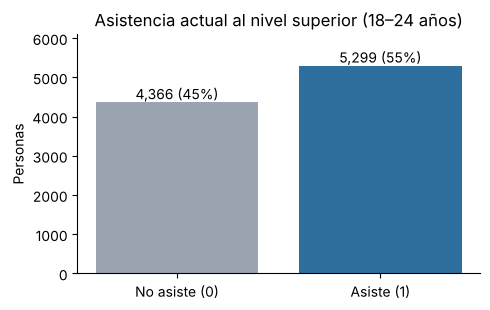

In [19]:
clases = dataset["asiste_superior"].value_counts().sort_index()
print(pd.DataFrame({"personas": clases, "%": (clases / clases.sum() * 100).round(1)}).rename(
    index={0: "0 · No asiste al nivel superior", 1: "1 · Asiste al nivel superior"}))

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.bar(["No asiste (0)", "Asiste (1)"], clases.values, color=["#9aa5b1", "#2f6f9f"])
for i, v in enumerate(clases.values):
    ax.text(i, v + 80, f"{v:,} ({v / clases.sum():.0%})", ha="center")
ax.set_ylabel("Personas")
ax.set_title("Asistencia actual al nivel superior (18–24 años)")
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, clases.max() * 1.15)
plt.tight_layout()
plt.savefig("../reports/figures/balance_clases.png", dpi=120)

Las clases están **equilibradas** (alrededor de 55 % / 45 %), por lo que no hace falta aplicar técnicas de balanceo. Igual se usará una división estratificada para conservar esta proporción en entrenamiento y prueba.

In [20]:
dataset.to_csv("../data/processed/eph_jovenes_asistencia_superior.csv", index=False)
print("Dataset guardado en data/processed/eph_jovenes_asistencia_superior.csv")

Dataset guardado en data/processed/eph_jovenes_asistencia_superior.csv


## Resumen

| | |
|---|---|
| Fuente | EPH continua – INDEC (2T 2025 a 1T 2026), descargada el 22/10/2026 |
| Archivos originales | 8 (4 bases de personas + 4 de hogares), 178.474 personas en total |
| Población | Jóvenes de 18 a 24 años con secundario completo, sin estudio superior terminado, residentes en 31 aglomerados urbanos |
| Observaciones de la población | 13.883 |
| Instancias del dataset final | 9.665 personas (una fila por persona) |
| Columnas | 26 (5 de identificación/diseño, 1 objetivo, 20 predictoras candidatas) |
| Variable objetivo | `asiste_superior` (1 = asiste actualmente al nivel superior) |
| Tipo de problema | Clasificación binaria supervisada |

Próximo paso (Entrega 3): análisis exploratorio, preparación (imputación, codificación, escalado) y entrenamiento de los modelos.